In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("amazon.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nRating distribution:")
print(df['rating'].value_counts(dropna=False).sort_index())

print("\nMissing values in selected columns:")
selected_columns = [
    'rating', 'actual_price', 'discounted_price',
    'discount_percentage', 'rating_count', 'category'
]
print(df[selected_columns].isnull().sum())

print("\nSample records:")
print(df[selected_columns].head())


Dataset shape: (1465, 16)

Columns:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']

Rating distribution:
rating
2        1
2.3      1
2.6      1
2.8      2
2.9      1
3        1
3.0      3
3.1      4
3.2      2
3.3     16
3.4     10
3.5     26
3.6     35
3.7     42
3.8     86
3.9    123
4       52
4.0    129
4.1    244
4.2    228
4.3    230
4.4    123
4.5     75
4.6     17
4.7      6
4.8      3
5.0      3
|        1
Name: count, dtype: int64

Missing values in selected columns:
rating                 0
actual_price           0
discounted_price       0
discount_percentage    0
rating_count           2
category               0
dtype: int64

Sample records:
  rating actual_price discounted_price discount_percentage rating_count  \
0    4.2       ₹1,099             ₹399                 64%       

In [2]:

task6 = df[
    [
        'rating',
        'actual_price',
        'discounted_price',
        'discount_percentage',
        'rating_count',
        'category'
    ]
].copy()
task6['rating'] = pd.to_numeric(task6['rating'], errors='coerce')
task6['actual_price'] = pd.to_numeric(
    task6['actual_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)
task6['discounted_price'] = pd.to_numeric(
    task6['discounted_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

task6['discount_percentage'] = pd.to_numeric(
    task6['discount_percentage'].astype(str)
    .str.replace('%', '', regex=False),
    errors='coerce'
)
task6['rating_count'] = pd.to_numeric(
    task6['rating_count'].astype(str)
    .str.replace(',', '', regex=False),
    errors='coerce'
)
task6['main_category'] = task6['category'].str.split('|').str[0]

print("Dataset shape:", task6.shape)
print("\nMissing values after conversion:")
print(task6[
    ['rating', 'actual_price', 'discounted_price',
     'discount_percentage', 'rating_count', 'main_category']
].isnull().sum())

print("\nMain categories:")
print(task6['main_category'].value_counts())

print("\nRating summary:")
print(task6['rating'].describe().round(3))


Dataset shape: (1465, 7)

Missing values after conversion:
rating                 1
actual_price           0
discounted_price       0
discount_percentage    0
rating_count           2
main_category          0
dtype: int64

Main categories:
main_category
Electronics              526
Computers&Accessories    453
Home&Kitchen             448
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

Rating summary:
count    1464.000
mean        4.097
std         0.292
min         2.000
25%         4.000
50%         4.100
75%         4.300
max         5.000
Name: rating, dtype: float64


In [3]:

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
numeric_features = [
    'actual_price',
    'discounted_price',
    'discount_percentage',
    'rating_count'
]
categorical_features = ['main_category']
model_data = task6.dropna(subset=['rating']).copy()

X = model_data[numeric_features + categorical_features]
y = model_data['rating']
log_numeric_features = [
    'actual_price', 'discounted_price', 'rating_count'
]
other_numeric_features = ['discount_percentage']

log_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log_transform', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

other_numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('log_numeric', log_pipeline, log_numeric_features),
    ('other_numeric', other_numeric_pipeline, other_numeric_features),
    ('category', categorical_pipeline, categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", X.shape[1])
print("Target: rating")


Training rows: 1171
Testing rows: 293
Features: 5
Target: rating


In [4]:

cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, pipeline in models.items():
    cv_scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error',
            'r2': 'r2'
        },
        n_jobs=-1
    )
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'CV MAE': -cv_scores['test_mae'].mean(),
        'CV RMSE': -cv_scores['test_rmse'].mean(),
        'CV R2': cv_scores['test_r2'].mean(),
        'Test MAE': mean_absolute_error(y_test, predictions),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'Test R2': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).round(4)
print(results_df.to_string(index=False))


            Model  CV MAE  CV RMSE  CV R2  Test MAE  Test RMSE  Test R2
Linear Regression  0.2039   0.2789 0.0959    0.1978     0.2607   0.1243
    Random Forest  0.1847   0.2658 0.1765    0.1847     0.2648   0.0965


In [5]:

rf_model = models['Random Forest']
lr_model = models['Linear Regression']

rf_predictions = rf_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)
error_analysis = X_test.copy()
error_analysis['actual_rating'] = y_test
error_analysis['predicted_rating'] = rf_predictions
error_analysis['absolute_error'] = abs(
    error_analysis['actual_rating'] -
    error_analysis['predicted_rating']
)

print("Largest Random Forest prediction errors:")
print(
    error_analysis.sort_values(
        'absolute_error', ascending=False
    )[
        ['actual_price', 'discounted_price',
         'discount_percentage', 'rating_count',
         'main_category', 'actual_rating',
         'predicted_rating', 'absolute_error']
    ].head(10).round(3).to_string()
)


Largest Random Forest prediction errors:
      actual_price  discounted_price  discount_percentage  rating_count          main_category  actual_rating  predicted_rating  absolute_error
324          999.0             249.0                   75           NaN  Computers&Accessories            5.0             3.857           1.143
1201         499.0             279.0                   44          28.0           Home&Kitchen            4.8             3.787           1.013
1251        1499.0             721.0                   52        2449.0           Home&Kitchen            3.1             4.087           0.987
1456        1200.0             498.0                   59         113.0           Home&Kitchen            3.2             4.111           0.911
275          999.0             399.0                   60          23.0            Electronics            3.3             4.154           0.854
1089        1699.0            1049.0                   38         111.0           Home&Kitchen 

Permutation importance:
            feature  importance_mean  importance_std
      main_category          0.02636         0.00429
       rating_count          0.01935         0.00511
discount_percentage          0.01466         0.00327
   discounted_price          0.01227         0.00242
       actual_price          0.01060         0.00198


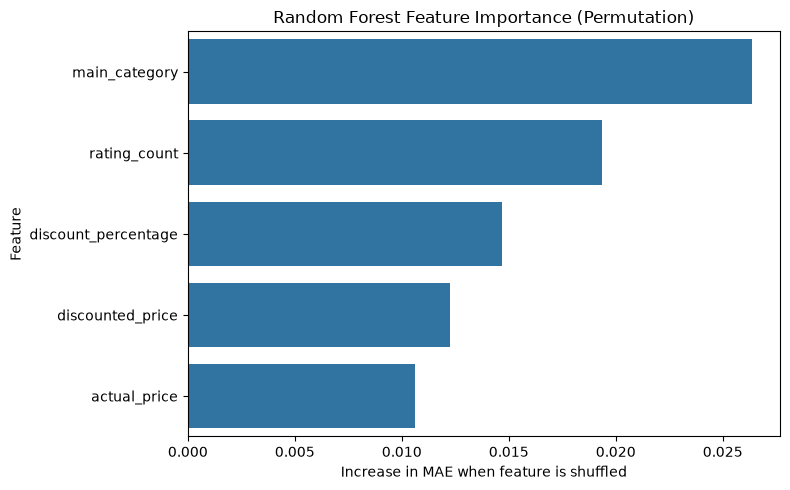

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=15,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': importance_result.importances_mean,
    'importance_std': importance_result.importances_std
}).sort_values('importance_mean', ascending=False)

print("Permutation importance:")
print(importance_df.round(5).to_string(index=False))


plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance_df,
    x='importance_mean',
    y='feature'
)
plt.title('Random Forest Feature Importance (Permutation)')
plt.xlabel('Increase in MAE when feature is shuffled')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
